## Notebook adapted from: C3S (https://confluence.ecmwf.int/pages/viewpage.action?pageId=540941752)
https://github.com/ecmwf-projects/dss-notebooks/blob/main/datasets/sis-energy-pecd/aggregation-pecd-regions-into-nut0/aggregation-pecd-regions-into-nut0.ipynb

In [45]:
import pandas as pd
import numpy as np
from pathlib import Path
import os
import glob
import matplotlib.pyplot as plt
import geopandas as gpd
import cartopy
from climate_year_selection.constants import BASE_INPUT, INPUT_DIR_WIND
from tqdm.notebook import tqdm

In [46]:
tech_type = "Offshore"  # "Onshore" or "Offshore"

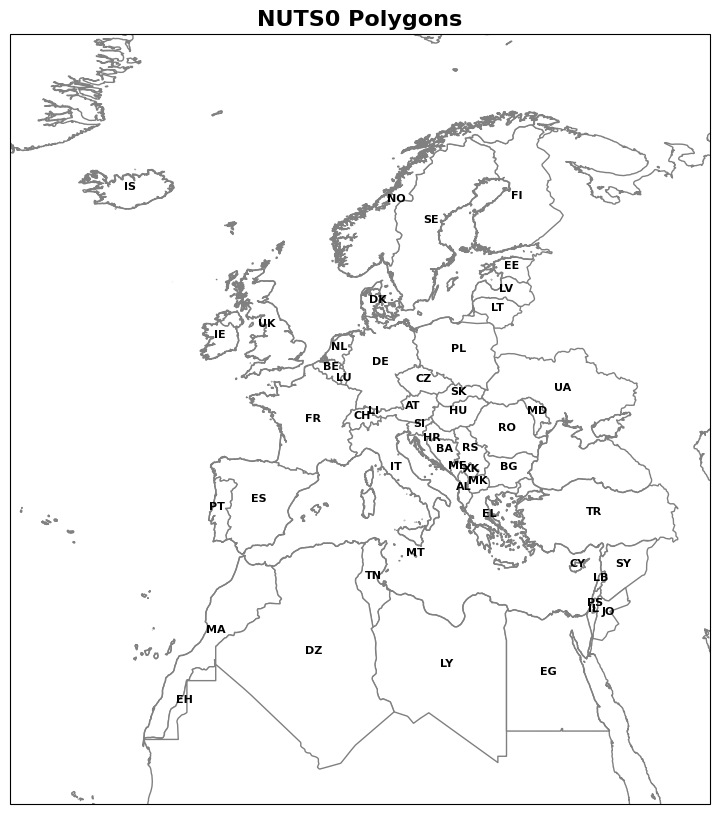

In [47]:
# Visualize NUTS0
# read shapefile
shp = gpd.read_file(
    "zip://./shapefiles/NUT0_ADM0_PECD.zip!NUT0_ADM0_PECD/NUT0_ADM0_PECDCODE.shp"
)
# Reproject to a suitable projected CRS (Europe example)
shp_proj = shp.to_crs(epsg=3035)  # ETRS89 / LAEA Europe

# make plot
fig = plt.figure(figsize=[10, 10])
map_proj = cartopy.crs.PlateCarree()
ax = plt.axes(projection=map_proj)
ax.coastlines(resolution="10m", color="grey")

shp.plot(color="white", edgecolors="grey", linewidths=1, ax=ax)

# Annotate with projected centroids transformed back to lon/lat
for i, row in shp_proj.iterrows():
    centroid = row.geometry.centroid
    # transform centroid back to original CRS for plotting
    centroid_lonlat = gpd.GeoSeries([centroid], crs=shp_proj.crs).to_crs(shp.crs)
    x, y = centroid_lonlat.geometry.iloc[0].coords[0]
    ax.text(
        x, y, row["PECD_CODE"], ha="center", fontsize=8, color="black", weight="bold"
    )

ax.set_title("NUTS0 Polygons", fontsize=16, fontweight="bold")
plt.show()


Text(0.5, 1.0, 'PECD v4.2 Offshore Polygons')

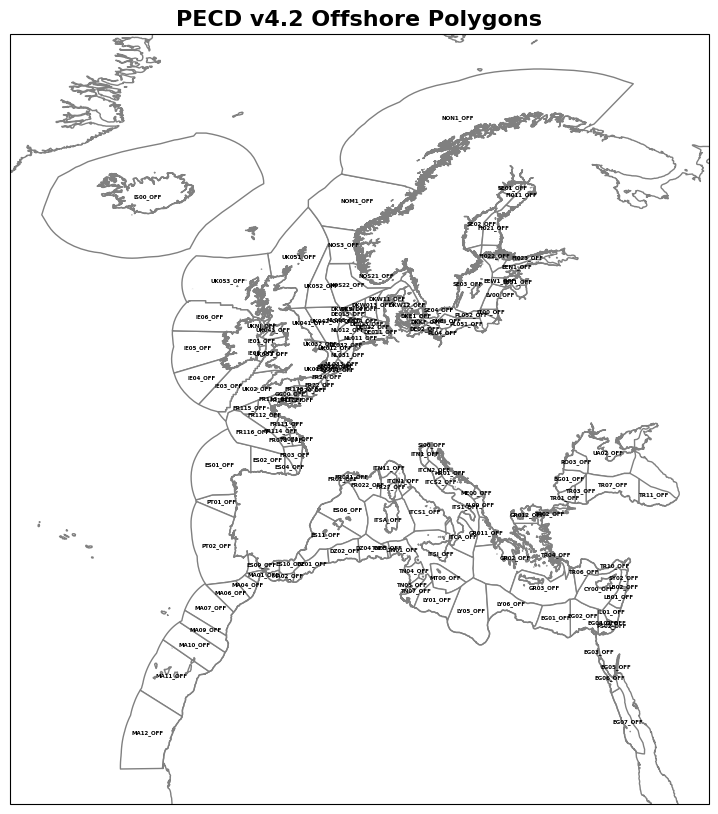

In [48]:
# Visualize PECD v4.2 Onshore/offshore Regsions
# read shapefile
shp = gpd.read_file(
    "zip://./shapefiles/PECD42_v2_final.zip!PECD42_v2_final/PECD42_v2_final.shp"
)
if tech_type == "Onshore":
    # keep only onshore regions
    shp = shp[~shp["Code"].str.contains("_OFF")]
elif tech_type == "Offshore":
    # keep only offshore regions
    shp = shp[shp["Code"].str.contains("_OFF")]

# Use a projected CRS appropriate for Europe (example: ETRS89 / LAEA Europe)
shp_proj = shp.to_crs(epsg=3035)  # Replace EPSG if your data is from another region

# make plot
fig = plt.figure(figsize=[10, 10])
map_proj = cartopy.crs.PlateCarree()
ax = plt.axes(projection=map_proj)
ax.coastlines(resolution="10m", color="grey")

shp.plot(color="white", edgecolors="grey", linewidths=1, ax=ax)

# --- Annotate using projected centroids ---
for i, row in shp_proj.iterrows():
    centroid = row.geometry.centroid
    # Convert centroid back to geographic coordinates (for plotting)
    centroid_geo = gpd.GeoSeries([centroid], crs=shp_proj.crs).to_crs(shp.crs)
    x, y = centroid_geo.geometry.iloc[0].coords[0]

    ax.text(x, y, row["Code"], ha="center", fontsize=4, color="black", weight="bold")

ax.set_title(f"PECD v4.2 {tech_type} Polygons", fontsize=16, fontweight="bold")

The figure above shows all onshore PECD v4.2 regions, each outlined in black and labeled with its corresponding regional code.
This quick check confirms that the shapefile has been read and filtered correctly — only onshore polygons are displayed, while offshore areas (codes containing _OFF) have been excluded.
The map provides a clear spatial reference for the next steps of the analysis, ensuring that the regional structure of the dataset is correctly interpreted before moving on to data aggregation and weighting.

### Create output folder where the final aggregated data will be saved

In [49]:
# Create output folder that will hold aggregated results
output_folder = f"{BASE_INPUT}/pecd_data/energy/wind/"
Path(output_folder).mkdir(parents=True, exist_ok=True)

### Reading the pre-calculated weights

In this example, we are aggregating existing wind technologies (i.e., the 2020 wind fleet), so the weights are read from PECD4.2/Onshore_Existing_run.csv. If we were working with a future onshore technology, the weights would instead be taken from Onshore_Future_tech_runs.csv.

In [50]:
# Define path to pre-calculated weights file
weight_file_pth = f"weights/PECD4.2/{tech_type}_Existing_run.csv"

# read in pre-calculated weights
reginfo = pd.read_csv(weight_file_pth)
print(reginfo)

    PECD_CODE PECD_STUDY_ZONE Country   NUTS0  Weight_in_aggregation  \
0   BE012_OFF        BE00_OFF  BE_OFF  BE_OFF                1774.75   
1   DE011_OFF        DE00_OFF  DE_OFF  DE_OFF                3974.92   
2   DE012_OFF        DE00_OFF  DE_OFF  DE_OFF                2655.22   
3    DE02_OFF        DE00_OFF  DE_OFF  DE_OFF                1088.90   
4    DKE1_OFF        DKE1_OFF  DK_OFF  DK_OFF                 423.40   
5   DKW11_OFF        DKW1_OFF  DK_OFF  DK_OFF                 776.00   
6   DKW12_OFF        DKW1_OFF  DK_OFF  DK_OFF                 456.20   
7    ES04_OFF        ES00_OFF  ES_OFF  ES_OFF                  20.00   
8   FI021_OFF        FI00_OFF  FI_OFF  FI_OFF                  44.30   
9   FR081_OFF        FR00_OFF  FR_OFF  FR_OFF                  10.20   
10   IE00_OFF        IE00_OFF  IE_OFF  IE_OFF                  25.20   
11  NL011_OFF        NL00_OFF  NL_OFF  NL_OFF                 600.00   
12  NL031_OFF        NL00_OFF  NL_OFF  NL_OFF                 35

### Building dictionaries with weighing factors

In [51]:
capacity_country_dict = dict()
country_region_dict = dict()

for iter1 in reginfo["NUTS0"].unique():
    mask = (reginfo["NUTS0"] == iter1) & (reginfo["Weight_in_aggregation"] > 0)
    country_region_dict[iter1] = list(reginfo["PECD_CODE"].loc[mask])
    capacity_country_dict[iter1] = sum(reginfo["Weight_in_aggregation"].loc[mask])

capacity_region_dict = dict()
for iter1 in reginfo["PECD_CODE"]:
    mask = reginfo["PECD_CODE"] == iter1
    capacity_region_dict[iter1] = reginfo["Weight_in_aggregation"].loc[mask].values[0]


print(capacity_region_dict)


{'BE012_OFF': 1774.75, 'DE011_OFF': 3974.92, 'DE012_OFF': 2655.22, 'DE02_OFF': 1088.9, 'DKE1_OFF': 423.4, 'DKW11_OFF': 776.0, 'DKW12_OFF': 456.2, 'ES04_OFF': 20.0, 'FI021_OFF': 44.3, 'FR081_OFF': 10.2, 'IE00_OFF': 25.2, 'NL011_OFF': 600.0, 'NL031_OFF': 357.0, 'NL033_OFF': 19.0, 'NOS21_OFF': 22.3, 'PT02_OFF': 25.0, 'SE03_OFF': 50.75, 'SE04_OFF': 110.4, 'UK011_OFF': 3285.5, 'UK031_OFF': 1072.0, 'UK032_OFF': 1756.5, 'UK041_OFF': 532.6, 'UK042_OFF': 1218.0, 'UK043_OFF': 1829.0, 'UK051_OFF': 718.2}


### Loading the Timeseries Data to be re-aggregated

In [52]:
# BASE_WIND_RAW = "/net/pc230050/nobackup/users/duinen/04_weather_year_selection/inputs/pecd_data/energy/wind_peof_peon/"
BASE_WIND_RAW = os.path.join(BASE_INPUT, "pecd_data/energy/wind_peof_peon/")
all_wind_files = sorted(glob.glob(os.path.join(BASE_WIND_RAW, "*.csv")))
# select only the files with the correct technology type in the filename
if tech_type == "Onshore":
    sel_wind_files = [f for f in all_wind_files if "WON" in f]
if tech_type == "Offshore":
    sel_wind_files = [f for f in all_wind_files if "WOF" in f]

In [53]:
def aggregate_regions_to_nut0(ts_fn):
    ts = pd.read_csv(ts_fn, comment="#", index_col="Date")
    weighted_df = ts.multiply(pd.Series(capacity_region_dict), axis=1)

    # Aggregate
    aggregated_data = {}
    for group, columns in country_region_dict.items():
        aggregated_data[group] = weighted_df[columns].sum(axis=1)

    # Create the final aggregated DataFrame
    aggregated_df = pd.DataFrame(aggregated_data)

    # Normalize by total capacity per country or region
    aggregated_df = aggregated_df.divide(pd.Series(capacity_country_dict), axis=1)

    # ## Save Results
    file_name = os.path.basename(ts_fn)
    output_file = Path(output_folder) / f"{file_name.split('.csv')[0]}_NUTS0_level.csv"
    aggregated_df.to_csv(output_file)

In [54]:
# Run aggregation for all files
for fn in tqdm(sel_wind_files):
    aggregate_regions_to_nut0(fn)

  0%|          | 0/192 [00:00<?, ?it/s]